In [1]:
%pip -q install "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-optimization==0.7.0" "qiskit-machine-learning==0.9.0" "koreanize-matplotlib==0.1.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
# ============================================
# 단기 채권 데이터 (30개)
# [return%, volatility%, liquidity(M$), credit_rating(1~10), duration(년), spread(bps), sentiment]
# ============================================

bond_data = np.array([
 [0.5, 4.5, 85, 9, 0.2, 30, 0.3],
 [0.7, 5.2, 80, 8, 0.3, 35, 0.2],
 [0.4, 3.8, 90,10, 0.1, 25, 0.4],
 [0.8, 5.8, 78, 7, 0.4, 40, 0.1],
 [0.6, 4.7, 83, 8, 0.3, 33, 0.3],
 [0.9, 6.2, 76, 6, 0.5, 45, 0.0],
 [0.5, 4.2, 87, 9, 0.2, 28, 0.4],
 [0.3, 3.5, 92,10, 0.1, 22, 0.5],
 [1.0, 6.5, 75, 6, 0.6, 47, -0.1],
 [0.7, 5.4, 82, 8, 0.3, 36, 0.2],
 [0.4, 3.9, 89, 9, 0.2, 26, 0.4],
 [0.6, 4.8, 84, 8, 0.3, 32, 0.3],
 [0.8, 5.7, 79, 7, 0.4, 38, 0.1],
 [0.5, 4.3, 86, 9, 0.2, 29, 0.4],
 [1.1, 6.8, 73, 5, 0.7, 50, -0.2],
 [0.3, 3.4, 93,10, 0.1, 21, 0.5],
 [0.7, 5.3, 81, 8, 0.3, 34, 0.2],
 [0.5, 4.4, 85, 9, 0.2, 31, 0.3],
 [0.9, 6.1, 77, 6, 0.5, 43, 0.0],
 [0.4, 3.7, 91, 9, 0.1, 24, 0.4],
 [0.8, 5.9, 78, 7, 0.4, 39, 0.1],
 [0.5, 4.1, 88, 9, 0.2, 27, 0.4],
 [1.0, 6.4, 74, 6, 0.6, 46, -0.1],
 [0.6, 4.9, 83, 8, 0.3, 32, 0.3],
 [0.7, 5.5, 80, 7, 0.4, 37, 0.2],
 [0.9, 6.0, 76, 6, 0.5, 44, 0.0],
 [0.4, 3.8, 90, 9, 0.2, 25, 0.4],
 [1.1, 6.9, 72, 5, 0.8, 51, -0.2],
 [0.5, 4.6, 84, 8, 0.3, 30, 0.3],
 [0.8, 5.6, 79, 7, 0.4, 38, 0.1],
], dtype=np.float32)

채권 바스켓 비용 VQE 후보: ['A'] 목적값: 0.301786
채권 바스켓 비용 QAOA 후보: ['B'] 목적값: 0.240714


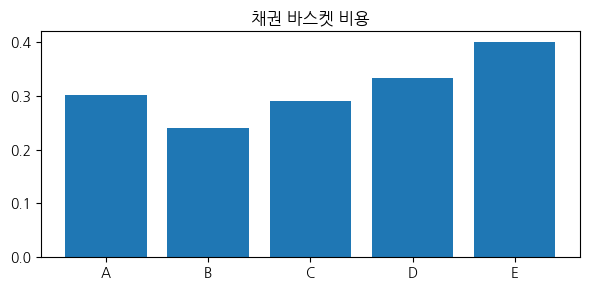

In [8]:
# QNN·VQE·QAOA 실행 코드
bond_report = extension_problem('채권', bond_data)
compare_baskets(bond_report, '채권 바스켓 비용')

In [9]:
# 추가 실습 코드 — 듀레이션 비중 바꾸기
normalized_bond = np.column_stack([minmax(bond_data[:,j]) for j in range(7)])
for duration_weight in [0.0, 0.2, 0.5]:
    other_weight = (1-duration_weight)/2
    alternative_risk = (other_weight*normalized_bond[:,1]
                        +other_weight*(1-normalized_bond[:,3])
                        +duration_weight*normalized_bond[:,4])
    alternative_cost = (0.5*alternative_risk+0.3*bond_report['friction']
                        -0.2*normalized_bond[:,0]+0.1*(1-normalized_bond[:,6]))
    basket_values = alternative_cost.reshape(5,6).mean(axis=1)
    print('듀레이션 비중:', duration_weight, '비용:', basket_values.round(4),
          '최저 바스켓:', list('ABCDE')[int(np.argmin(basket_values))])

듀레이션 비중: 0.0 비용: [0.3165 0.25   0.3029 0.3482 0.4111] 최저 바스켓: B
듀레이션 비중: 0.2 비용: [0.3018 0.2407 0.2912 0.3335 0.4001] 최저 바스켓: B
듀레이션 비중: 0.5 비용: [0.2796 0.2268 0.2737 0.3113 0.3837] 최저 바스켓: B


In [11]:
# 세 확장 사례의 결과를 한 번에 비교
for title, report in [('ESG', esg_report), ('암호화폐', crypto_report), ('채권', bond_report)]:
    minimum = float(np.min(report['basket_cost']))
    vqe_cost = float(report['basket_cost'] @ report['vqe_bits'])
    qaoa_cost = float(report['basket_cost'] @ report['qaoa_bits'])
    test_rows = report['test']
    accuracy = np.mean((report['probabilities'][test_rows] >= 0.5) == report['labels'][test_rows])
    print(f'{title}: QNN 평가 정확도={accuracy:.3f}, 정확 최솟값={minimum:.6f}, '
          f'VQE 차이={vqe_cost-minimum:.6f}, QAOA 차이={qaoa_cost-minimum:.6f}')

ESG: QNN 평가 정확도=1.000, 정확 최솟값=0.300822, VQE 차이=0.029609, QAOA 차이=0.029609
암호화폐: QNN 평가 정확도=1.000, 정확 최솟값=0.337922, VQE 차이=0.004934, QAOA 차이=0.000000
채권: QNN 평가 정확도=0.889, 정확 최솟값=0.240714, VQE 차이=0.061071, QAOA 차이=0.000000
